# Brent and WTI forecasting with XGBoost and regimes

One model class, two targets: gradient-boosted trees (XGBoost) that forecast the cumulative Brent and WTI
futures log return 1, 5, 10, 20, 30, 40, 50 and 60 trading days ahead, one model per target and horizon
(direct forecasts). Forecasts are converted to prices.
Inputs: about 20 candidate predictors, reduced in every training window to one representative variable per
principal component (PCA variable selection, not PCA regression), plus a market regime.
Benchmarks required by the brief: no-change (RW), historical mean, AR(1).

**Regimes.** A two-state Markov-switching model of daily returns (calm / turbulent) is re-estimated in every
training window. A causal label turns its filtered probability into regimes that last at least
**65 trading days (one quarter)**. The probability and the label enter the trees as two extra inputs.

**Economic value.** Trade each oil on its own forecast (long / short / flat) and compare with buy-and-hold and a
vol-targeted long position, per unit of risk. Every holding period is reported.

**Sample split**

| Block | Dates | Role |
|---|---|---|
| In-sample | each fit's 1,260-day window (about 5 years) | training; the last 252 days of the window are an inner validation set for early stopping |
| Out-of-sample backtest | forecast origins 2016-01-01 to 2026-09-30 | evaluation; every forecast uses only data up to its origin |
| Live test | origins from 2026-10-01 | untouched test period; forecasts logged daily |

**Run.** `pip install xgboost` (and `numba` for speed), open from `OilForecastQF`, run all cells.
Results go to `Outputs/xgb/brent` and `Outputs/xgb/wti`.

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy import stats
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=RuntimeWarning)
PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd() / "OilForecastQF", Path.cwd().parent)
                     if (p / "Data" / "raw" / "yahoo_daily.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open the notebook from OilForecastQF (needs Data/raw/yahoo_daily.csv).")
RUN_LEAK_CHECK = False          # True: re-run a short backtest on scrambled future data (a few minutes)
pd.set_option("display.width", 180)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#E6E8EB", "font.size": 10})

/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/heiheidaaaaaa/opt/anaconda3/lib/python3.9/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Settings

In [2]:
@dataclass
class Config:
    data_dir: Path = PROJECT_ROOT / "Data" / "raw"
    output_dir: Path = PROJECT_ROOT / "Outputs" / "xgb"
    targets: tuple = ("brent_fut", "wti_fut")
    horizons: tuple = (1, 5, 10, 20, 30, 40, 50, 60)   # one direct model per horizon (trading days)
    report_h: tuple = (1, 5, 10, 20, 30, 40, 50, 60)   # horizons shown in the tables
    oos_start: str = "2016-01-01"      # first out-of-sample forecast origin
    test_start: str = "2026-10-01"     # live test period
    window: int = 1260                 # rolling training window (trading days, about 5 years)
    refit_every: int = 21              # re-train every 21 trading days (about monthly)
    inner_val: int = 252               # last 252 days of each window: early-stopping validation
    ffill_limit: int = 3
    fred_lag: int = 1                  # FRED daily series enter one observation late
    # XGBoost: shallow trees, slow learning, row/column subsampling, strong L2 penalty
    n_estimators: int = 500
    learning_rate: float = 0.03
    max_depth: int = 3
    min_child_weight: float = 50
    subsample: float = 0.7
    colsample_bytree: float = 0.7
    reg_lambda: float = 10.0
    early_stopping: int = 50
    seed: int = 7
    shrink: float = 0.5                # final forecast = 0.5 x tree forecast (equal-weight combination with no change)
    use_pca: bool = True               # False: train on all candidate features (comparison in section 6.3)
    pca_min_eig: float = 1.0           # PCA variable selection: keep components with eigenvalue > 1 (Kaiser)
    use_season: bool = False           # day-of-year features off: they overfit in a 5-year window
    # regimes
    use_regime: bool = True            # add P(turbulent) and the regime label as inputs
    min_duration: int = 65             # regimes expected to last >= 65 days, and labels kept >= 65 days (a quarter)
    enter_p: float = 0.7               # label: switch to turbulent if P(turbulent) > 0.7 ...
    exit_p: float = 0.3                # ... back to calm if P(turbulent) < 0.3 ...
    confirm: int = 10                  # ... for 10 consecutive days
    # plots
    plot_h: int = 20
    path_years: int = 4                # forecast-path chart: last 4 years of out-of-sample origins
    # trading rules (fixed in advance)
    cost_bps: float = 5.0              # per unit of turnover, per leg
    trade_hs: tuple = (5, 10, 20)      # holding period = forecast horizon; 20 days is the main rule
    main_trade_h: int = 20
    noise_k: float = 0.1               # trade only if |forecast| > 0.1 x expected h-day volatility
    target_vol: float = 25.0           # % annual volatility target
    max_leverage: float = 2.0
    compare_vol: float = 10.0          # comparison: every strategy rescaled to 10% annual volatility


cfg = Config()
NAMES = {"brent_fut": "Brent", "wti_fut": "WTI"}
for sub in ("brent", "wti"):
    (cfg.output_dir / sub).mkdir(parents=True, exist_ok=True)
OUT = {"brent_fut": cfg.output_dir / "brent", "wti_fut": cfg.output_dir / "wti"}
NT = len(cfg.targets)

## 2. Data and features

Sources: `Data/raw/yahoo_daily.csv`; `Data/raw/fred_daily.csv` if present (lagged one observation).
The calendar is the set of days on which both Brent and WTI futures trade, so the two models use the same dates. Other series are forward-filled for at most 3 days; non-positive prices are set to
missing. XGBoost handles missing values itself, so no imputation.

About 20 candidate predictors per target, chosen on economic grounds, all known at the close of day $t$.
The own-market block uses the oil being forecast (Brent or WTI); every other block is shared.

**Every feature is a change or a z-score, never a raw level.** A tree cannot extrapolate: if a level
(VIX, OVX, the yield spread) moves outside the range of its training window, as in 2020 and 2022, the
tree treats it like the most extreme value it has seen. A z-score measures the value against its own past
year: $z_t=(v_t-\text{mean}_{252})/\text{sd}_{252}$.

| Block | Features | Idea |
|---|---|---|
| Own momentum and trend | log returns over 1, 5, 20, 60 days; log gap to 50- and 200-day averages | momentum, reversal, trend |
| Volatility | 20/60-day realized volatility ratio; z-scores of 60-day realized volatility and VIX | calm vs turbulent market |
| Oil market | z-scores of Brent–WTI spread and 3-2-1 crack spread; crack spread 20-day change | regional balance, refining margin |
| Cross-market (20-day log return) | natural gas, XLE, S&P 500, dollar index, gold, copper, and USD/CAD, USD/NOK, EEM if present | energy equities, risk appetite, dollar, industrial demand |
| Macro (FRED, if present) | 10Y–3M spread 60-day change; OVX z-score; 10Y breakeven 20-day change | business cycle, oil risk, inflation |
| Regime (section 3) | P(turbulent), regime label | calm vs turbulent, at least one quarter long |

In [3]:
def load_data(cfg):
    raw = pd.read_csv(cfg.data_dir / "yahoo_daily.csv", parse_dates=["date"]).set_index("date").sort_index()
    raw = raw[~raw.index.duplicated(keep="last")].select_dtypes("number")
    raw = raw.where(raw > 0)
    prices = raw[["brent_fut", "wti_fut"]].dropna()           # days on which both futures trade
    other = raw.drop(columns=["brent_fut", "wti_fut"])
    fred_path = cfg.data_dir / "fred_daily.csv"
    if fred_path.is_file():
        fred = pd.read_csv(fred_path, parse_dates=["date"]).set_index("date").sort_index().select_dtypes("number")
        keep = [c for c in ("t10y3m", "ovx", "breakeven10y") if c in fred]
        fred = fred[keep].dropna(how="all").shift(cfg.fred_lag)       # published the next day
        other = other.join(fred, how="outer")
    other = other.reindex(other.index.union(prices.index)).ffill(limit=cfg.ffill_limit).reindex(prices.index)
    return prices, other


def zscore(s, n=252):
    roll = s.rolling(n, min_periods=int(0.8 * n))
    return (s - roll.mean()) / roll.std()


def build_features(prices, other, target, cfg):
    tag = NAMES[target].lower()
    price = prices[target]
    lp = np.log(price)
    r = lp.diff()
    vol = pd.DataFrame({"rv20": r.rolling(20, min_periods=15).std() * np.sqrt(252),
                        "rv60": r.rolling(60, min_periods=45).std() * np.sqrt(252)})
    f = {f"{tag}_ret{k}": lp.diff(k) for k in (1, 5, 20, 60)}
    f[f"{tag}_gap_ma50"] = lp - np.log(price.rolling(50, min_periods=40).mean())
    f[f"{tag}_gap_ma200"] = lp - np.log(price.rolling(200, min_periods=160).mean())
    f["rv_ratio"] = vol["rv20"] / vol["rv60"]
    f["rv60_z"] = zscore(vol["rv60"])
    if "vix" in other:
        f["vix_z"] = zscore(other["vix"])
    f["brent_wti_z"] = zscore(np.log(prices["brent_fut"]) - np.log(prices["wti_fut"]))
    if {"gasoline", "heating_oil"} <= set(other.columns):
        cl = prices["wti_fut"]
        crack = ((2 * 42 * other["gasoline"] + 42 * other["heating_oil"] - 3 * cl) / 3 / cl).where(lambda s: s.abs() < 2)
        f["crack_z"], f["crack_d20"] = zscore(crack), crack.diff(20)
    for c in ("natgas", "xle", "sp500", "dxy", "gold", "copper", "usdcad", "usdnok", "eem"):
        if c in other and other[c].notna().sum() > 500:
            f[f"{c}_ret20"] = np.log(other[c]).diff(20)
    if "t10y3m" in other:
        f["t10y3m_d60"] = other["t10y3m"].diff(60)
    if "ovx" in other:
        f["ovx_z"] = zscore(other["ovx"])
    if "breakeven10y" in other:
        f["breakeven_d20"] = other["breakeven10y"].diff(20)
    if cfg.use_season:
        doy = price.index.dayofyear.to_numpy()
        f["season_sin"] = pd.Series(np.sin(2 * np.pi * doy / 365.25), index=price.index)
        f["season_cos"] = pd.Series(np.cos(2 * np.pi * doy / 365.25), index=price.index)
    X = pd.DataFrame(f, index=price.index).replace([np.inf, -np.inf], np.nan)
    Y = {h: 100 * (lp.shift(-h) - lp) for h in cfg.horizons}         # cumulative h-day log return, %
    return X, Y, lp, vol


prices, other = load_data(cfg)
DATA = {}
for tgt in cfg.targets:
    X_, Y_, lp_, vol_ = build_features(prices, other, tgt, cfg)
    DATA[tgt] = {"X": X_, "Y": Y_, "lp": lp_, "vol": vol_}
    pd.concat([prices[tgt], X_], axis=1).rename_axis("date").to_csv(OUT[tgt] / "model_panel.csv")
display(pd.DataFrame({NAMES[t]: {"first date": prices.index[0].date(), "last date": prices.index[-1].date(),
                                 "observations": len(prices), "number of features": DATA[t]["X"].shape[1]}
                      for t in cfg.targets}))
for t in cfg.targets:
    display(Markdown(f"**{NAMES[t]} features:** " + ", ".join(f"`{c}`" for c in DATA[t]["X"].columns)))

,Brent,WTI
first date,2007-07-30,2007-07-30
last date,2026-10-28,2026-10-28
observations,4792,4792
number of features,21,21


**Brent features:** `brent_ret1`, `brent_ret5`, `brent_ret20`, `brent_ret60`, `brent_gap_ma50`, `brent_gap_ma200`, `rv_ratio`, `rv60_z`, `vix_z`, `brent_wti_z`, `crack_z`, `crack_d20`, `natgas_ret20`, `xle_ret20`, `sp500_ret20`, `dxy_ret20`, `gold_ret20`, `copper_ret20`, `t10y3m_d60`, `ovx_z`, `breakeven_d20`

**WTI features:** `wti_ret1`, `wti_ret5`, `wti_ret20`, `wti_ret60`, `wti_gap_ma50`, `wti_gap_ma200`, `rv_ratio`, `rv60_z`, `vix_z`, `brent_wti_z`, `crack_z`, `crack_d20`, `natgas_ret20`, `xle_ret20`, `sp500_ret20`, `dxy_ret20`, `gold_ret20`, `copper_ret20`, `t10y3m_d60`, `ovx_z`, `breakeven_d20`

## 2b. PCA variable selection

Many candidate features measure overlapping things (risk appetite, trend, the dollar). PCA is used only to
**choose which original variables to keep**; the model is then trained on those original variables, not on
principal components (this is not a PCA regression).

Method (Jolliffe 1972, method B4), on the training window only:

1. Standardize the candidate features and compute the eigenvalues and loadings of their correlation matrix.
2. Keep the components with eigenvalue above 1 (Kaiser rule).
3. For each kept component, in order, select the original variable with the largest absolute loading that has not been selected yet.

The selection uses only the features, never the target. It is repeated inside every rolling window.
The regime inputs are added after the selection and are always kept. Below: the latest window.

In [4]:
def pca_select(A, names, min_eig=1.0):
    """Jolliffe B4: one original variable per retained principal component."""
    D = pd.DataFrame(A, columns=names)
    D = D.loc[:, D.notna().mean() > 0.8]                       # ignore features mostly missing in the window
    D = D.fillna(D.mean())
    Z = (D - D.mean()) / D.std().replace(0, np.nan)
    Z = Z.dropna(axis=1)
    eig, vec = np.linalg.eigh(np.corrcoef(Z.to_numpy().T))
    order = np.argsort(eig)[::-1]
    eig, vec = eig[order], vec[:, order]
    k = max(1, int((eig > min_eig).sum()))
    load = pd.DataFrame(vec[:, :k], index=Z.columns, columns=[f"PC{j + 1}" for j in range(k)])
    chosen = []
    for j in range(k):
        for v in load.iloc[:, j].abs().sort_values(ascending=False).index:
            if v not in chosen:
                chosen.append(v)
                break
    sel = [list(names).index(v) for v in chosen]
    return sel, eig, load


rows_pca = []
for t in cfg.targets:
    X = DATA[t]["X"]
    Nw = len(X)
    sel_now, eig_now, load_now = pca_select(X.to_numpy(np.float32)[Nw - cfg.window:Nw], X.columns, cfg.pca_min_eig)
    for c, pc in zip(sel_now, load_now.columns):
        rows_pca.append({"target": NAMES[t], "component": pc, "eigenvalue": round(eig_now[int(pc[2:]) - 1], 2),
                         "selected variable": X.columns[c], "loading": round(load_now.loc[X.columns[c], pc], 2)})
display(Markdown("**Variables selected by PCA in the latest window**"))
display(pd.DataFrame(rows_pca).set_index(["target", "component"]))

**Variables selected by PCA in the latest window**

eigenvalue selected variable  loading
target component                                       
Brent  PC1              4.58    brent_gap_ma50    -0.42
       PC2              3.02      copper_ret20    -0.33
       PC3              2.02          rv_ratio    -0.38
       PC4              1.61           crack_z     0.41
       PC5              1.50       sp500_ret20    -0.39
       PC6              1.15      natgas_ret20     0.41
       PC7              1.09        brent_ret1    -0.44
WTI    PC1              4.56      wti_gap_ma50    -0.42
       PC2              3.08             vix_z     0.34
       PC3              2.00        gold_ret20     0.35
       PC4              1.53           crack_z     0.46
       PC5              1.50          wti_ret1     0.45
       PC6              1.17      natgas_ret20     0.42
       PC7              1.13       sp500_ret20     0.44

## 3. Regimes (minimum one quarter)

For each target, a two-state Markov-switching model of daily log returns with regime-specific mean and
variance (Hamilton filter, Kim smoother, EM):

$$r_t = \mu_{s_t} + \sigma_{s_t}\varepsilon_t,\qquad s_t\in\{\text{calm},\text{turbulent}\},\qquad P(s_t=j\mid s_{t-1}=j)=p_{jj}\ge 1-\tfrac{1}{65}$$

The constraint on $p_{jj}$ makes the expected length of each regime at least 65 trading days.
The model is re-estimated on each training window (every 21 days) and only its **filtered** probability is used,
so the value on day $t$ uses returns up to $t$.

**Label.** A state machine run once through the whole sample, day by day: switch to turbulent when
P(turbulent) stays above 0.7 for 10 days, back to calm when it stays below 0.3 for 10 days, and never before the
current regime has lasted 65 days.

regime models: 3s


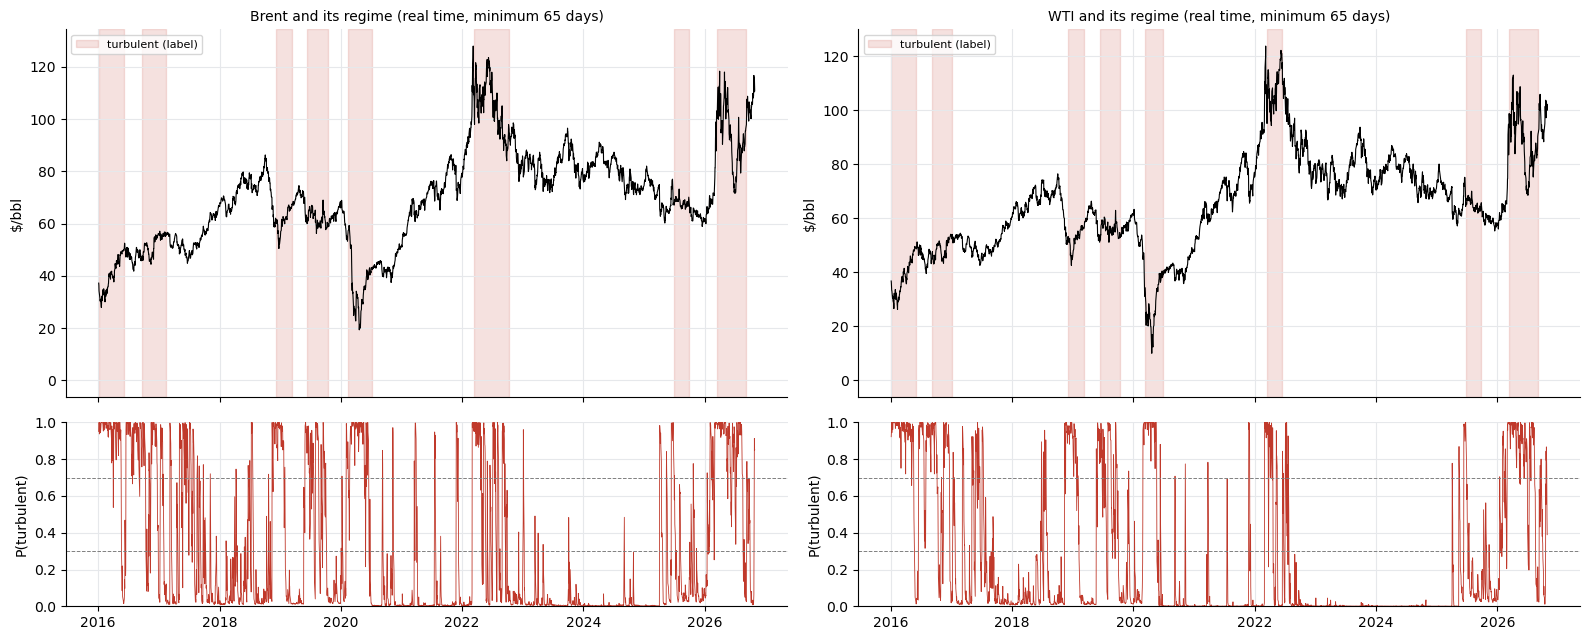

**Brent regime spells** (16 spells since the first origin; shortest complete spell: 65 days; the first and the current spell are cut by the sample)

,regime,start,end,trading_days
0,turbulent,2016-01-04,2016-06-02,105
1,calm,2016-06-03,2016-09-20,76
2,turbulent,2016-09-21,2017-02-10,97
3,calm,2017-02-13,2018-12-03,456
4,turbulent,2018-12-04,2019-03-11,65
5,calm,2019-03-12,2019-06-12,65
6,turbulent,2019-06-13,2019-10-18,90
7,calm,2019-10-21,2020-02-13,80
8,turbulent,2020-02-14,2020-07-09,100
9,calm,2020-07-10,2022-03-14,423


**WTI regime spells** (16 spells since the first origin; shortest complete spell: 65 days; the first and the current spell are cut by the sample)

,regime,start,end,trading_days
0,turbulent,2016-01-04,2016-06-03,106
1,calm,2016-06-06,2016-09-06,65
2,turbulent,2016-09-07,2017-01-05,82
3,calm,2017-01-06,2018-12-03,481
4,turbulent,2018-12-04,2019-03-11,65
5,calm,2019-03-12,2019-06-12,65
6,turbulent,2019-06-13,2019-10-15,87
7,calm,2019-10-16,2020-03-11,101
8,turbulent,2020-03-12,2020-06-25,73
9,calm,2020-06-26,2022-03-11,431


In [5]:
try:
    from numba import njit
except Exception:                                   # missing or broken numba: plain Python (slower)
    def njit(*a, **k):
        return a[0] if a and callable(a[0]) else (lambda f: f)


@njit(cache=False)
def _ms_filter(y, mu, sig, P, xi0):
    # pred[t] = P(s_t | data before t), filt[t] = P(s_t | data up to t)
    T = y.shape[0]
    filt = np.empty((T, 2)); pred = np.empty((T, 2))
    p0, p1, ll = xi0[0], xi0[1], 0.0
    c = 1.0 / np.sqrt(2.0 * np.pi)
    for t in range(T):
        pred[t, 0] = p0; pred[t, 1] = p1
        z0 = (y[t] - mu[0]) / sig[0]; z1 = (y[t] - mu[1]) / sig[1]
        a0 = p0 * c / sig[0] * np.exp(-0.5 * z0 * z0)
        a1 = p1 * c / sig[1] * np.exp(-0.5 * z1 * z1)
        s = max(a0 + a1, 1e-300)
        ll += np.log(s)
        g0 = a0 / s; g1 = a1 / s
        filt[t, 0] = g0; filt[t, 1] = g1
        p0 = g0 * P[0, 0] + g1 * P[1, 0]
        p1 = 1.0 - p0
    return filt, pred, ll


@njit(cache=False)
def _ms_smooth(filt, pred, P):
    T = filt.shape[0]
    sm = np.empty((T, 2)); xs = np.zeros((2, 2))
    sm[T - 1, 0] = filt[T - 1, 0]; sm[T - 1, 1] = filt[T - 1, 1]
    for t in range(T - 2, -1, -1):
        r0 = sm[t + 1, 0] / max(pred[t + 1, 0], 1e-300)
        r1 = sm[t + 1, 1] / max(pred[t + 1, 1], 1e-300)
        for i in range(2):
            a = filt[t, i] * P[i, 0] * r0
            b = filt[t, i] * P[i, 1] * r1
            sm[t, i] = a + b
            xs[i, 0] += a; xs[i, 1] += b
    return sm, xs


class RegimeModel:
    """Two-state Markov-switching mean/variance model with minimum expected regime length."""

    def __init__(self, min_duration=65, max_iter=200, tol=1e-7):
        self.p_min, self.max_iter, self.tol = 1 - 1 / min_duration, max_iter, tol

    @staticmethod
    def stationary(P):
        den = 2 - P[0, 0] - P[1, 1]
        x0 = (1 - P[1, 1]) / den if den > 1e-12 else 0.5
        return np.array([x0, 1 - x0])

    def _em(self, y, mu, sig, P):
        floor, prev = 0.05 * y.std(), -np.inf
        for _ in range(self.max_iter):
            filt, pred, ll = _ms_filter(y, mu, sig, P, self.stationary(P))
            sm, xs = _ms_smooth(filt, pred, P)
            for j in range(2):
                w = sm[:, j] + 1e-10
                mu[j] = np.sum(w * y) / w.sum()
                sig[j] = max(np.sqrt(np.sum(w * (y - mu[j]) ** 2) / w.sum()), floor)
            P = xs / xs.sum(1, keepdims=True)
            for j in range(2):
                if P[j, j] < self.p_min:
                    P[j, j], P[j, 1 - j] = self.p_min, 1 - self.p_min
            if ll - prev < self.tol * abs(ll):
                break
            prev = ll
        return mu, sig, P, _ms_filter(y, mu, sig, P, self.stationary(P))[2]

    def fit(self, y, warm=None):
        vol = pd.Series(y).rolling(20, min_periods=5).std().bfill().to_numpy()
        g = vol > np.median(vol)
        d = max(0.995, self.p_min)
        starts = [(np.array([y[~g].mean(), y[g].mean()]), np.array([y[~g].std(), y[g].std()]),
                   np.array([[d, 1 - d], [1 - d, d]]))]
        if warm is not None:
            starts.append((warm.mu.copy(), warm.sig.copy(), warm.P.copy()))
        mu, sig, P, ll = max((self._em(y, *[a.copy() for a in s]) for s in starts), key=lambda res: res[3])
        o = np.argsort(sig)                          # 0 = calm, 1 = turbulent
        self.mu, self.sig, self.P, self.loglik = mu[o], sig[o], P[o][:, o], ll
        return self

    def p_turbulent(self, y):
        return _ms_filter(y, self.mu, self.sig, self.P, self.stationary(self.P))[0][:, 1]


class RegimeLabel:
    """Causal label: switch only after `confirm` days beyond the threshold, and never before the current
    regime has lasted `min_duration` days."""

    def __init__(self, cfg):
        self.cfg, self.state, self.run, self.since = cfg, None, 0, cfg.min_duration

    def step(self, v):
        c = self.cfg
        if self.state is None:
            self.state = int(v > 0.5)
        self.since += 1
        cross = v > c.enter_p if self.state == 0 else v < c.exit_p
        self.run = self.run + 1 if cross else 0
        if self.run >= c.confirm and self.since >= c.min_duration:
            self.state, self.run, self.since = 1 - self.state, 0, 0
        return self.state


def first_origin(dates, cfg):
    return max(int(dates.searchsorted(pd.Timestamp(cfg.oos_start))), cfg.window + 200)


def regime_path(lp, cfg):
    """Real-time P(turbulent) and label. Rows before the first origin (training history of the first window)
    are labelled once with the first model; every later value uses returns and parameters known at that day."""
    dates, N = lp.index, len(lp)
    rr = 100 * lp.diff().to_numpy()
    start = first_origin(dates, cfg)
    refits = list(range(start, N, cfg.refit_every))
    p_turb, lab = np.full(N, np.nan), np.full(N, np.nan)
    machine, rmodel, log = RegimeLabel(cfg), None, []
    for k, i0 in enumerate(refits):
        i1 = refits[k + 1] if k + 1 < len(refits) else N
        lo = i0 - cfg.window
        rmodel = RegimeModel(cfg.min_duration).fit(np.nan_to_num(rr[lo + 1:i0 + 1]), warm=rmodel)
        p = rmodel.p_turbulent(np.nan_to_num(rr[lo:i1]))
        first = lo if k == 0 else i0
        p_turb[first:i1] = p[first - lo:]
        for t in range(first, i1):
            lab[t] = machine.step(p_turb[t])
        log.append({"refit": dates[i0], "vol_calm_ann_%": rmodel.sig[0] * np.sqrt(252),
                    "vol_turb_ann_%": rmodel.sig[1] * np.sqrt(252),
                    "p_stay_calm": rmodel.P[0, 0], "p_stay_turb": rmodel.P[1, 1]})
    return pd.DataFrame({"p_turb": p_turb, "label": lab}, index=dates), pd.DataFrame(log).set_index("refit")


t0 = time.time()
for t in cfg.targets:
    DATA[t]["reg"], DATA[t]["reg_log"] = regime_path(DATA[t]["lp"], cfg)
    DATA[t]["reg"].to_csv(OUT[t] / "regimes.csv"); DATA[t]["reg_log"].to_csv(OUT[t] / "regime_parameters.csv")
print(f"regime models: {time.time() - t0:.0f}s")

fig, axes = plt.subplots(2, NT, figsize=(7 * NT + 2, 6.5), sharex=True, squeeze=False, gridspec_kw={"height_ratios": [2, 1]})
spell_tabs = {}
for j, t in enumerate(cfg.targets):
    reg = DATA[t]["reg"].iloc[first_origin(prices.index, cfg):]
    px = prices[t].reindex(reg.index)
    ax = axes[0, j]
    ax.plot(px.index, px, color="black", lw=0.8)
    ax.fill_between(reg.index, 0, 1, where=(reg["label"] == 1).to_numpy(), color="#C0392B", alpha=0.15,
                    transform=ax.get_xaxis_transform(), label="turbulent (label)")
    ax.set_title(f"{NAMES[t]} and its regime (real time, minimum {cfg.min_duration} days)", fontsize=10)
    ax.set_ylabel("$/bbl"); ax.legend(fontsize=8, loc="upper left")
    axes[1, j].plot(reg.index, reg["p_turb"], color="#C0392B", lw=0.6)
    for v in (cfg.enter_p, cfg.exit_p):
        axes[1, j].axhline(v, color="grey", ls="--", lw=0.7)
    axes[1, j].set_ylabel("P(turbulent)"); axes[1, j].set_ylim(0, 1)
    lab = reg["label"]
    sid = (lab != lab.shift()).cumsum()
    spell_tabs[NAMES[t]] = pd.DataFrame({"regime": lab.groupby(sid).first().map({0.0: "calm", 1.0: "turbulent"}),
                                         "start": lab.index.to_series().groupby(sid).first().dt.date,
                                         "end": lab.index.to_series().groupby(sid).last().dt.date,
                                         "trading_days": lab.groupby(sid).size()}).reset_index(drop=True)
    spell_tabs[NAMES[t]].to_csv(OUT[t] / "regime_spells.csv", index=False)
fig.tight_layout(); fig.savefig(cfg.output_dir / "regimes.png", dpi=150); plt.show()
for name, sp in spell_tabs.items():
    inner = sp["trading_days"].iloc[1:-1]
    display(Markdown(f"**{name} regime spells** ({len(sp)} spells since the first origin; shortest complete spell: "
                     f"{int(inner.min()) if len(inner) else 'n/a'} days; the first and the current spell are cut by the sample)"))
    display(sp)

## 4. Model

For each target and horizon $h$, a separate model (direct multi-step forecast):

$$y_{t,h} = 100\,(\log P_{t+h}-\log P_t) = F_h(x_t) + e_{t,h},\qquad F_h(x)=\sum_{m=1}^{M} \eta\, f_m(x)$$

where each $f_m$ is a regression tree fitted to the residuals of the previous trees.

| Setting | Value | Why |
|---|---|---|
| Tree depth | 3 | interactions of up to three variables, e.g. a predictor that matters only in the turbulent regime |
| Learning rate $\eta$ | 0.03 | small steps |
| Trees $M$ | up to 500, early stopping after 50 rounds without improvement on the inner validation set | the data choose how complex the model gets |
| Minimum observations per leaf | 50 | no leaf built on a handful of days |
| Row / column subsampling | 70% / 70% | less overfitting, less dependence on any one variable |
| L2 penalty on leaf values | 10 | shrinks forecasts toward zero |
| Starting value | 0 | with no signal, the forecast equals the no-change forecast |
| Final forecast | $\hat y_{t,h} = 0.5\,F_h(x_t)$ | equal-weight combination with the no-change forecast |

**Why shrink by half.** With $f$ the tree forecast and $y$ the outcome,
$\text{MSE}(\lambda f)=\text{MSE}(0)-2\lambda E[fy]+\lambda^2E[f^2]$: when the signal is weak, a smaller $\lambda$ cuts
the error from noise faster than it loses signal. The unshrunk forecast is reported as `XGB_raw`.

Hyperparameters and the shrink weight are fixed in advance and not tuned on the backtest.

In [6]:
def make_model(cfg, n_estimators=None):
    return xgb.XGBRegressor(n_estimators=n_estimators or cfg.n_estimators, learning_rate=cfg.learning_rate,
                            max_depth=cfg.max_depth, min_child_weight=cfg.min_child_weight,
                            subsample=cfg.subsample, colsample_bytree=cfg.colsample_bytree,
                            reg_lambda=cfg.reg_lambda, base_score=0.0, tree_method="hist",
                            objective="reg:squarederror", random_state=cfg.seed, n_jobs=4,
                            early_stopping_rounds=cfg.early_stopping)


def fit_one(A, y, scale, i0, h, cfg):
    """Train for origin i0: rows s with s + h <= i0 (targets already observed).
    Split: fit rows | gap of h days | last `inner_val` rows for early stopping.
    Interval: quantiles of errors / scale over the whole window, scale = 20-day vol over h days."""
    lo, hi = i0 - cfg.window, i0 - h + 1                       # rows lo..hi-1
    v0 = hi - cfg.inner_val
    fit_rows = np.arange(lo, v0 - h)
    val_rows = np.arange(v0, hi)
    fit_rows = fit_rows[np.isfinite(y[fit_rows])]
    val_rows = val_rows[np.isfinite(y[val_rows])]
    m = make_model(cfg)
    m.fit(A[fit_rows], y[fit_rows], eval_set=[(A[val_rows], y[val_rows])], verbose=False)
    rows = np.r_[fit_rows, val_rows]
    z = (y[rows] - cfg.shrink * m.predict(A[rows])) / scale[rows]
    q = np.nanquantile(z, [0.025, 0.10, 0.90, 0.975])          # standardized error quantiles
    return m, q, fit_rows, val_rows


def design(A, R, sel, cfg):
    """Selected original features, plus the regime inputs if enabled."""
    return np.column_stack([A[:, sel], R]) if cfg.use_regime else A[:, sel]

## 5. Rolling training and forecasts

- **Rolling window:** each model is trained on the previous 1,260 trading days. For horizon $h$, the last training row is $t-h$, so every target is already observed at the forecast date.
- **Inner validation:** inside each window, the last 252 days are held out (with an $h$-day gap) to decide when to stop adding trees.
- **Intervals:** forecast errors in the window divided by the 20-day realized volatility scaled to $h$ days; their 2.5/10/90/97.5% quantiles multiplied by today's volatility.
- **Re-training:** every 21 trading days from 2016-01-01, for each target separately. Between re-trainings the model is fixed and forecasts every day with that day's features and regime.
- **Benchmarks** on the same dates and window: RW (no change), HistMean (window mean h-day return), AR(1) on daily returns, iterated.
- **In-sample forecasts:** the latest model of each horizon applied to its own training rows.

Brent: 130 re-trainings x 8 horizons, 53s. First origin 2016-01-04, last 2026-10-28.
WTI: 130 re-trainings x 8 horizons, 47s. First origin 2016-01-04, last 2026-10-28.


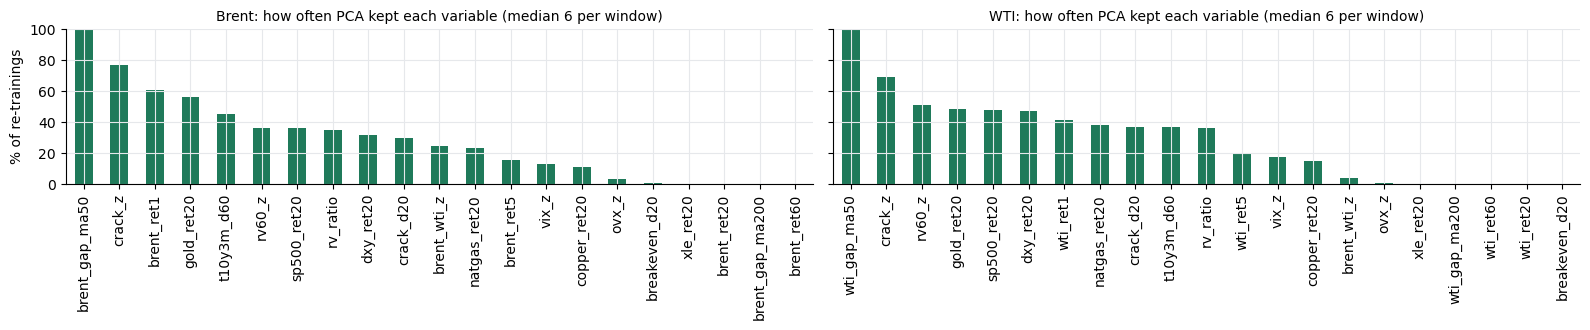

**Trees kept by early stopping** (median over re-trainings)

h,1,5,10,20,30,40,50,60
Brent,6.5,6.5,4.0,3.0,4.0,3.5,3.0,2.5
WTI,10.5,5.0,3.0,3.0,3.0,3.0,3.0,3.0


In [7]:
def run_backtest(X, Y, lp, vol, reg, cfg, verbose=True, label=""):
    dates, N = X.index, len(X)
    A = X.to_numpy(np.float32)
    R = reg[["p_turb", "label"]].to_numpy(np.float32)
    rr = 100 * lp.diff().to_numpy()
    rv = vol["rv20"].to_numpy()
    start = first_origin(dates, cfg)
    refits = list(range(start, N, cfg.refit_every))
    out = {h: {k: np.full(N, np.nan) for k in ("XGB", "XGB_raw", "q025", "q10", "q90", "q975", "HistMean", "AR")}
           for h in cfg.horizons}
    imp, ntrees, ins, sel_log, t0 = [], [], {}, [], time.time()
    for k, i0 in enumerate(refits):
        i1 = refits[k + 1] if k + 1 < len(refits) else N
        sel = (pca_select(A[i0 - cfg.window + 1:i0 + 1], X.columns, cfg.pca_min_eig)[0]   # features known at i0
               if cfg.use_pca else list(range(X.shape[1])))
        names = [X.columns[c] for c in sel] + (["p_turbulent", "regime_label"] if cfg.use_regime else [])
        As = design(A, R, sel, cfg)
        sel_log.append({"refit": dates[i0], **{X.columns[c]: 1 for c in sel}})
        w = rr[i0 - cfg.window + 1:i0 + 1]
        c, phi = np.polynomial.polynomial.polyfit(w[:-1], w[1:], 1)
        for h in cfg.horizons:
            y = Y[h].to_numpy()
            scale = 100 * rv * np.sqrt(h / 252)
            m, q, fit_rows, val_rows = fit_one(As, y, scale, i0, h, cfg)
            o = out[h]
            o["XGB_raw"][i0:i1] = m.predict(As[i0:i1])
            o["XGB"][i0:i1] = cfg.shrink * o["XGB_raw"][i0:i1]
            for name, qq in zip(("q025", "q10", "q90", "q975"), q):
                o[name][i0:i1] = qq * scale[i0:i1]
            o["HistMean"][i0:i1] = np.nanmean(y[i0 - cfg.window:i0 - h + 1])
            cur, acc = rr[i0:i1].copy(), np.zeros(i1 - i0)
            for _ in range(h):
                cur = c + phi * cur
                acc = acc + cur
            o["AR"][i0:i1] = acc
            gain = m.get_booster().get_score(importance_type="total_gain")
            imp.append({"refit": dates[i0], "h": h, **{names[int(f[1:])]: g for f, g in gain.items()}})
            ntrees.append({"refit": dates[i0], "h": h, "trees": m.best_iteration + 1})
            if k == len(refits) - 1:
                ins[h] = {"model": m, "rows": fit_rows, "q": q, "scale": scale, "val_rows": val_rows,
                          "As": As, "names": names}
    if verbose:
        print(f"{label}{len(refits)} re-trainings x {len(cfg.horizons)} horizons, {time.time() - t0:.0f}s. "
              f"First origin {dates[start].date()}, last {dates[-1].date()}.")
    imp = pd.DataFrame(imp).fillna(0.0)
    sel_log = pd.DataFrame(sel_log).fillna(0).set_index("refit").reindex(columns=X.columns, fill_value=0)
    return out, imp, pd.DataFrame(ntrees), ins, sel_log


for t in cfg.targets:
    d = DATA[t]
    d["out"], d["importance"], d["ntrees"], d["ins"], d["sel_log"] = run_backtest(
        d["X"], d["Y"], d["lp"], d["vol"], d["reg"], cfg, label=f"{NAMES[t]}: ")
    d["ntrees"].to_csv(OUT[t] / "trees_per_fit.csv", index=False)
    d["sel_log"].to_csv(OUT[t] / "pca_selection_log.csv")

fig, axes = plt.subplots(1, NT, figsize=(7 * NT + 2, 3.4), sharey=True, squeeze=False)
for ax, t in zip(axes[0], cfg.targets):
    sl = DATA[t]["sel_log"]
    (100 * sl.mean()).sort_values(ascending=False).plot.bar(ax=ax, color="#1F7A5A")
    ax.set_ylim(0, 100); ax.set_ylabel("% of re-trainings")
    ax.set_title(f"{NAMES[t]}: how often PCA kept each variable (median {int(sl.sum(axis=1).median())} per window)", fontsize=10)
plt.tight_layout(); plt.savefig(cfg.output_dir / "pca_selection_frequency.png", dpi=150); plt.show()
display(Markdown("**Trees kept by early stopping** (median over re-trainings)"))
display(pd.concat({NAMES[t]: DATA[t]["ntrees"].groupby("h")["trees"].median() for t in cfg.targets}, axis=1).T)

In [8]:
def to_long(cols_by_h, lp, rows_by_h, sample=None):
    dates, N, P, L = lp.index, len(lp), np.exp(lp.to_numpy()), lp.to_numpy()
    recs = []
    for h, rows in rows_by_h.items():
        t = np.asarray(rows)
        tgt = t + h
        has = tgt < N
        d = pd.DataFrame({"origin": dates[t], "h": h,
                          "target_date": [dates[j] if j < N else pd.NaT for j in tgt], "P_t": P[t],
                          "y": np.where(has, L[np.minimum(tgt, N - 1)] - L[t], np.nan), "RW": 0.0})
        for name, arr in cols_by_h[h].items():
            d[name] = arr[t] / 100
        recs.append(d)
    fc = pd.concat(recs, ignore_index=True)
    fc["P_target"] = fc["P_t"] * np.exp(fc["y"])
    test = pd.Timestamp(cfg.test_start)
    fc["sample"] = sample or np.where(fc["origin"] >= test, "Live test",
                                      np.where(fc["target_date"] < test, "Out-of-sample", "straddles test start"))
    return fc


for t in cfg.targets:
    d = DATA[t]
    out = d["out"]
    d["fc"] = to_long(out, d["lp"], {h: np.flatnonzero(np.isfinite(out[h]["XGB"])) for h in cfg.horizons})
    ins_cols, ins_rows = {}, {}
    for h, e in d["ins"].items():
        arr = {k: np.full(len(d["X"]), np.nan) for k in ("XGB", "XGB_raw", "q025", "q10", "q90", "q975")}
        arr["XGB_raw"][e["rows"]] = e["model"].predict(e["As"][e["rows"]])
        arr["XGB"][e["rows"]] = cfg.shrink * arr["XGB_raw"][e["rows"]]
        for name, v in zip(("q025", "q10", "q90", "q975"), e["q"]):
            arr[name][e["rows"]] = v * e["scale"][e["rows"]]
        ins_cols[h], ins_rows[h] = arr, e["rows"]
    d["fc_in"] = to_long(ins_cols, d["lp"], ins_rows, sample="In-sample")
    d["fc"].to_csv(OUT[t] / "forecasts_out_of_sample.csv", index=False)
    d["fc_in"].to_csv(OUT[t] / "forecasts_in_sample.csv", index=False)
display(pd.concat({NAMES[t]: DATA[t]["fc"].groupby("sample")["origin"].agg(["min", "max", "count"]) for t in cfg.targets}))

min        max  count
      sample                                           
Brent Live test            2026-10-01 2026-10-28    176
      Out-of-sample        2016-01-04 2026-09-29  21384
      straddles test start 2026-07-08 2026-09-30    216
WTI   Live test            2026-10-01 2026-10-28    176
      Out-of-sample        2016-01-04 2026-09-29  21384
      straddles test start 2026-07-08 2026-09-30    216

## 6. Results

### 6.1 In-sample vs out-of-sample accuracy

Price errors in \$/bbl. **RMSE ratio vs RW** below 1 means the model beats the no-change forecast.
DM p-value: one-sided Diebold–Mariano test (Harvey–Leybourne–Newbold correction, Newey–West variance) that the model has lower squared price error than RW.
Direction: hit rate, and precision / recall / F1 for "price goes up"; `up_share_%` is the share of up moves. Coverage: share of outcomes inside the 80% and 95% intervals.

In [9]:
def dm_pvalue(e_m, e_b, h):
    d = e_m ** 2 - e_b ** 2
    n = len(d)
    if n < 30 or np.allclose(d, 0):
        return np.nan
    u = d - d.mean()
    v = u @ u / n + 2 * sum((1 - k / h) * (u[k:] @ u[:-k]) / n for k in range(1, h))
    if v <= 0:
        return np.nan
    stat = d.mean() / np.sqrt(v / n) * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return stats.t.cdf(stat, n - 1)


def evaluate(df, models):
    rows = []
    for (h, smp), g in df.dropna(subset=["y"]).groupby(["h", "sample"]):
        e_rw = g["P_t"] - g["P_target"]
        for m in models:
            if m not in g or g[m].isna().all():
                continue
            e = g["P_t"] * np.exp(g[m]) - g["P_target"]
            row = {"sample": smp, "h": h, "model": m, "n": len(g), "MAE_$": e.abs().mean(),
                   "RMSE_$": np.sqrt((e ** 2).mean()), "MAPE_%": 100 * (e.abs() / g["P_target"]).mean(),
                   "RMSE_ratio_vs_RW": np.sqrt((e ** 2).mean() / (e_rw ** 2).mean())}
            if m != "RW":
                row["DM_p"] = dm_pvalue(e.to_numpy(), e_rw.to_numpy(), h)
                up_hat, up = g[m] > 0, g["y"] > 0
                tp = (up_hat & up).sum()
                prec, rec = tp / max(up_hat.sum(), 1), tp / max(up.sum(), 1)
                row.update({"hit_%": 100 * (up_hat == up).mean(), "up_share_%": 100 * up.mean(),
                            "precision_up": prec, "recall_up": rec,
                            "F1_up": 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0})
            if m == "XGB":
                res = g["y"] - g[m]
                row["cover80_%"] = 100 * ((res >= g["q10"]) & (res <= g["q90"])).mean()
                row["cover95_%"] = 100 * ((res >= g["q025"]) & (res <= g["q975"])).mean()
            rows.append(row)
    return pd.DataFrame(rows)


MODELS = ["RW", "HistMean", "AR", "XGB_raw", "XGB"]
for t in cfg.targets:
    d = DATA[t]
    d["met"] = evaluate(pd.concat([d["fc_in"], d["fc"][d["fc"]["sample"].isin(["Out-of-sample", "Live test"])]]), MODELS)
    d["met"].to_csv(OUT[t] / "metrics.csv", index=False)
    d["xm"] = d["met"][d["met"]["model"] == "XGB"]


def side_by_side(value):
    tabs = {}
    for t in cfg.targets:
        xm = DATA[t]["xm"]
        order = [c for c in ["In-sample", "Out-of-sample", "Live test"] if c in set(xm["sample"])]
        tabs[NAMES[t]] = xm.pivot(index="h", columns="sample", values=value)[order]
    return pd.concat(tabs, axis=1).reindex(list(cfg.report_h)).round(3)


display(Markdown("**XGBoost: price RMSE ratio vs RW, in-sample vs out-of-sample**"))
display(side_by_side("RMSE_ratio_vs_RW"))
display(Markdown("**XGBoost: direction hit rate %**"))
display(side_by_side("hit_%"))

**XGBoost: price RMSE ratio vs RW, in-sample vs out-of-sample**

Brent                               WTI                        
sample In-sample Out-of-sample Live test In-sample Out-of-sample Live test
h                                                                         
1          0.990         1.001     0.998     0.998         1.000     1.002
5          0.999         1.005     1.003     0.999         1.001     1.000
10         0.985         1.001     1.013     0.999         1.000     1.000
20         0.998         1.000     1.007     0.999         0.996     1.001
30         0.994         0.999       NaN     0.998         1.003       NaN
40         0.995         1.000       NaN     0.969         1.004       NaN
50         0.998         1.003       NaN     0.927         1.003       NaN
60         0.998         1.004       NaN     0.995         0.998       NaN

**XGBoost: direction hit rate %**

Brent                               WTI                        
sample In-sample Out-of-sample Live test In-sample Out-of-sample Live test
h                                                                         
1         61.072        49.500    57.143    60.377        49.759    42.857
5         61.361        49.202    41.176    57.457        50.835    76.471
10        67.543        48.848    25.000    58.241        51.078     0.000
20        62.745        51.045     0.000    60.578        50.410     0.000
30        63.541        52.884       NaN    58.588        50.599       NaN
40        67.492        56.504       NaN    73.089        47.707       NaN
50        63.476        54.717       NaN    70.517        49.472       NaN
60        56.355        52.008       NaN    69.629        48.598       NaN

In [10]:
for t in cfg.targets:
    oos = DATA[t]["met"][DATA[t]["met"]["sample"] == "Out-of-sample"]
    display(Markdown(f"**{NAMES[t]}, out-of-sample, all models: price RMSE ratio vs RW**"))
    display(oos.pivot(index="model", columns="h", values="RMSE_ratio_vs_RW").loc[MODELS, list(cfg.report_h)].round(3))
    display(Markdown(f"**{NAMES[t]}, out-of-sample, XGBoost in detail**"))
    cols = ["h", "n", "MAE_$", "RMSE_$", "MAPE_%", "RMSE_ratio_vs_RW", "DM_p", "hit_%", "up_share_%", "precision_up",
            "recall_up", "F1_up", "cover80_%", "cover95_%"]
    display(oos[(oos["model"] == "XGB") & oos["h"].isin(cfg.report_h)][cols].round(3).set_index("h"))

**Brent, out-of-sample, all models: price RMSE ratio vs RW**

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.000,1.002,1.006,1.012,1.017,1.021,1.023,1.026
AR,1.002,1.003,1.006,1.011,1.017,1.021,1.024,1.027
XGB_raw,1.003,1.011,1.004,1.005,1.006,1.007,1.011,1.012
XGB,1.001,1.005,1.001,1.000,0.999,1.000,1.003,1.004


**Brent, out-of-sample, XGBoost in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.194,1.824,1.747,1.001,0.992,49.500,53.872,0.535,0.482,0.507,80.030,94.702
5,2695,2.717,3.930,4.051,1.005,0.992,49.202,54.471,0.537,0.487,0.511,78.887,94.434
10,2690,3.774,5.337,5.709,1.001,0.600,48.848,56.022,0.554,0.448,0.495,79.591,94.015
20,2680,5.242,7.371,7.903,1.000,0.469,51.045,57.239,0.586,0.492,0.535,78.769,93.806
30,2670,6.384,8.946,9.791,0.999,0.453,52.884,56.105,0.591,0.519,0.553,79.288,92.097
40,2660,7.424,10.430,11.552,1.000,0.472,56.504,55.677,0.623,0.555,0.587,76.241,92.293
50,2650,8.397,11.724,13.082,1.003,0.739,54.717,53.811,0.596,0.493,0.540,78.491,91.321
60,2640,9.085,12.749,14.206,1.004,0.770,52.008,54.129,0.565,0.493,0.527,76.742,90.606


**WTI, out-of-sample, all models: price RMSE ratio vs RW**

h,1,5,10,20,30,40,50,60
model,,,,,,,,
RW,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
HistMean,1.000,1.003,1.006,1.012,1.017,1.021,1.024,1.027
AR,1.002,1.003,1.005,1.011,1.016,1.020,1.023,1.026
XGB_raw,1.002,1.003,1.004,0.997,1.011,1.011,1.010,1.004
XGB,1.000,1.001,1.000,0.996,1.003,1.004,1.003,0.998


**WTI, out-of-sample, XGBoost in detail**

,n,MAE_$,RMSE_$,MAPE_%,RMSE_ratio_vs_RW,DM_p,hit_%,up_share_%,precision_up,recall_up,F1_up,cover80_%,cover95_%
h,,,,,,,,,,,,,
1,2699,1.204,1.799,1.935,1.000,0.611,49.759,53.724,0.538,0.464,0.498,80.104,94.813
5,2695,2.703,3.880,4.351,1.001,0.689,50.835,54.100,0.550,0.499,0.523,79.035,94.137
10,2690,3.734,5.258,6.139,1.000,0.593,51.078,56.245,0.581,0.466,0.517,78.662,93.606
20,2680,5.255,7.253,8.693,0.996,0.099,50.410,55.410,0.558,0.502,0.529,79.366,92.799
30,2670,6.444,8.928,10.894,1.003,0.794,50.599,56.330,0.574,0.475,0.520,80.150,92.921
40,2660,7.502,10.377,12.947,1.004,0.948,47.707,56.203,0.542,0.453,0.493,78.684,92.293
50,2650,8.269,11.575,14.352,1.003,0.798,49.472,54.906,0.551,0.432,0.484,78.113,91.849
60,2640,8.868,12.471,15.431,0.998,0.345,48.598,53.220,0.521,0.421,0.466,77.765,92.159


### 6.2 What the forecasts look like

**Forecast paths.** Every 21 trading days, the 1-to-60-day forecast path is drawn from that day's price
(green: model expects a rise over 60 days; red: a fall; grey: no view, |60-day forecast| < 0.1%).
Black is the realized price; the live test period is shaded.

**Does the forecast sort the outcomes?** Forecasts are split into five equal groups, from the most bearish (Q1) to the most bullish (Q5).
If the model has signal, the realized return rises from Q1 to Q5. IC is the rank correlation between forecast and outcome.

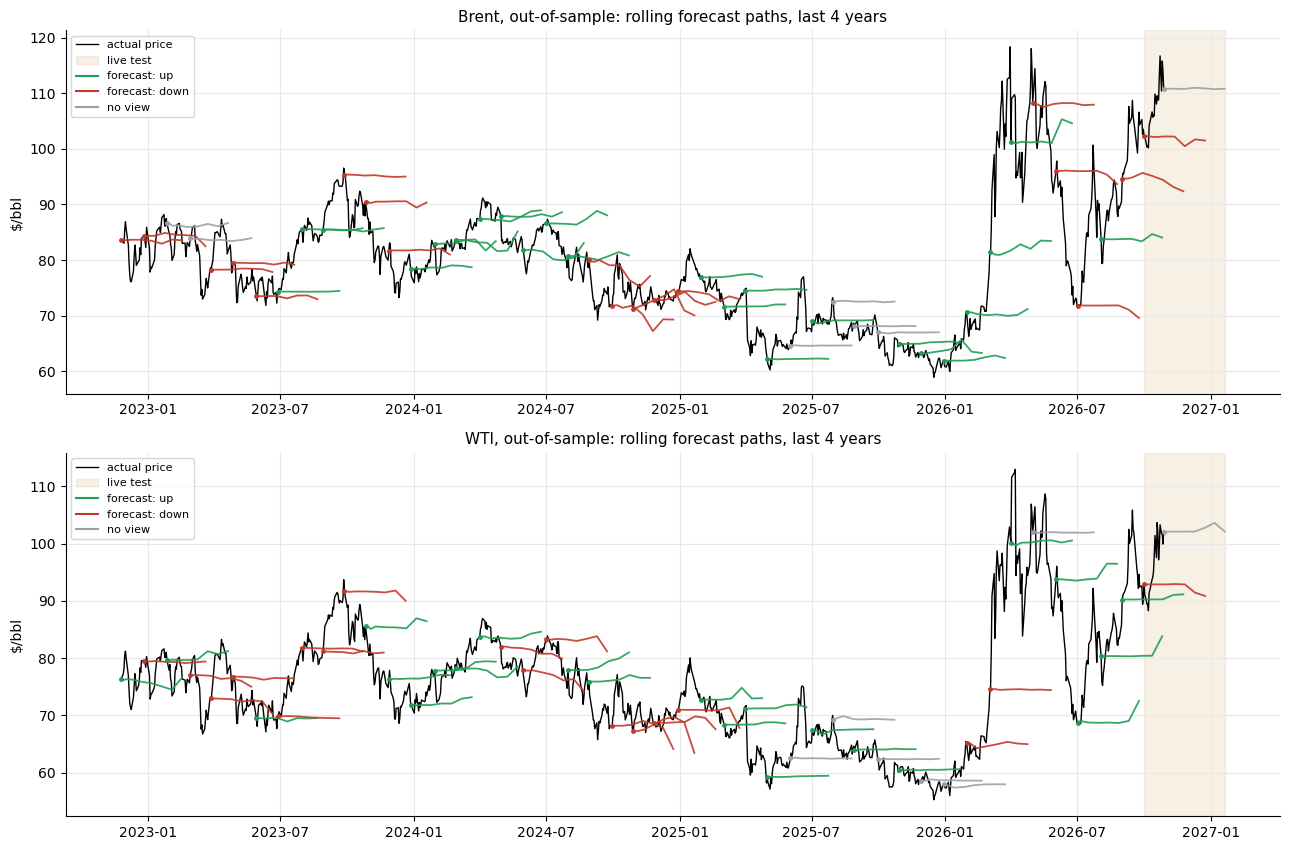

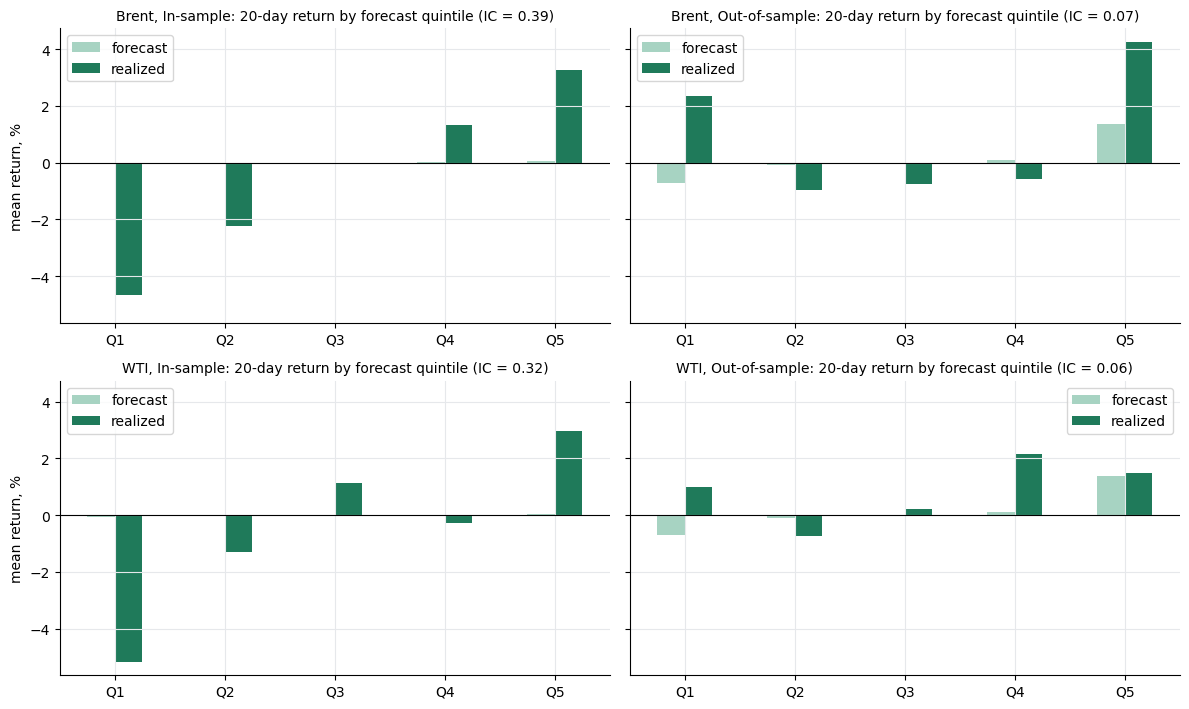

,target,sample,h,IC,Q5 - Q1 realized (%)
0,Brent,In-sample,20,0.391,7.959
1,Brent,Out-of-sample,20,0.069,1.926
2,WTI,In-sample,20,0.323,8.124
3,WTI,Out-of-sample,20,0.061,0.482


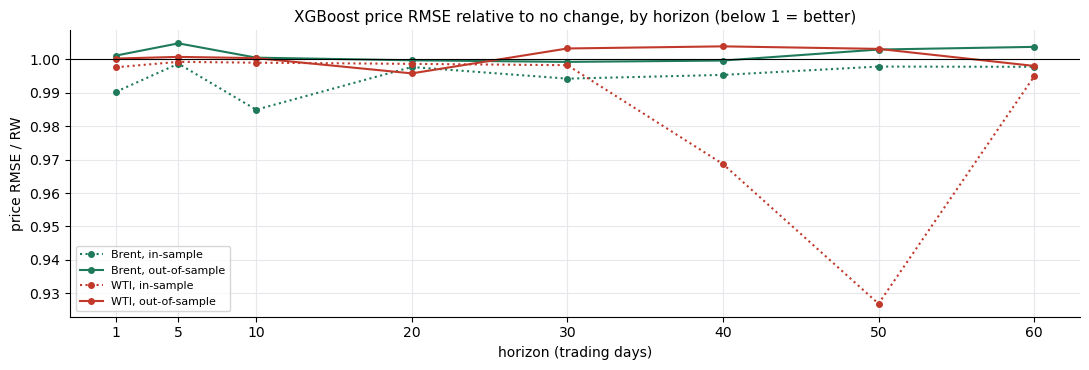

In [11]:
def paths(df, origins):
    piv = df.pivot_table(index="origin", columns="h", values="XGB")
    p0 = df.drop_duplicates("origin").set_index("origin")["P_t"]
    for o in origins:
        if o not in piv.index or piv.loc[o].isna().any():
            continue
        xs = [o] + [o + pd.offsets.BDay(int(h)) for h in piv.columns]
        ys = [p0[o]] + list(p0[o] * np.exp(piv.loc[o].to_numpy()))
        last = piv.loc[o].to_numpy()[-1]
        yield xs, ys, (0 if abs(last) < 1e-3 else (1 if last > 0 else -1))


fig, axes = plt.subplots(NT, 1, figsize=(13, 4.3 * NT), squeeze=False)
for ax, t in zip(axes[:, 0], cfg.targets):
    fc = DATA[t]["fc"]
    oos_fc = fc[fc["sample"].isin(["Out-of-sample", "Live test", "straddles test start"])]
    o_orig = np.sort(oos_fc["origin"].unique())
    o_orig = o_orig[o_orig >= o_orig[-1] - np.timedelta64(365 * cfg.path_years, "D")][::-1][::21][::-1]
    lo_d, hi_d = pd.Timestamp(o_orig[0]), pd.Timestamp(o_orig[-1]) + pd.offsets.BDay(60)
    act = prices[t].loc[lo_d:hi_d]
    ax.plot(act.index, act, color="black", lw=1.0, label="actual price")
    for xs, ys, view in paths(oos_fc, o_orig):
        col_ = {1: "#1F9D55", -1: "#C0392B", 0: "#9AA0A6"}[view]
        ax.plot(xs, ys, color=col_, lw=1.3, alpha=0.9)
        ax.plot(xs[0], ys[0], "o", color=col_, ms=2.5)
    ax.axvspan(pd.Timestamp(cfg.test_start), hi_d, color="#C38728", alpha=0.12, label="live test")
    ax.plot([], [], color="#1F9D55", label="forecast: up"); ax.plot([], [], color="#C0392B", label="forecast: down")
    ax.plot([], [], color="#9AA0A6", label="no view")
    ax.set_title(f"{NAMES[t]}, out-of-sample: rolling forecast paths, last {cfg.path_years} years", fontsize=11)
    ax.set_ylabel("$/bbl"); ax.legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(cfg.output_dir / "forecast_paths.png", dpi=150); plt.show()

h = cfg.plot_h
fig, axes = plt.subplots(NT, 2, figsize=(12, 3.6 * NT), sharey=True, squeeze=False)
ic_rows = []
for j, t in enumerate(cfg.targets):
    for i, smp in enumerate(["In-sample", "Out-of-sample"]):
        ax = axes[j, i]
        src = DATA[t]["fc_in"] if smp == "In-sample" else DATA[t]["fc"][DATA[t]["fc"]["sample"] == "Out-of-sample"]
        g = src[src["h"] == h].dropna(subset=["y", "XGB"]).copy()
        g["Q"] = pd.qcut(g["XGB"].rank(method="first"), 5, labels=[f"Q{k}" for k in range(1, 6)])
        b = g.groupby("Q", observed=True).agg(forecast=("XGB", "mean"), realized=("y", "mean")) * 100
        b.plot.bar(ax=ax, color=["#A7D3C2", "#1F7A5A"], rot=0)
        ic = stats.spearmanr(g["XGB"], g["y"]).correlation
        ic_rows.append({"target": NAMES[t], "sample": smp, "h": h, "IC": ic,
                        "Q5 - Q1 realized (%)": b["realized"].iloc[-1] - b["realized"].iloc[0]})
        ax.axhline(0, color="black", lw=0.8)
        ax.set_title(f"{NAMES[t]}, {smp}: {h}-day return by forecast quintile (IC = {ic:.2f})", fontsize=10)
        ax.set_xlabel(""); ax.set_ylabel("mean return, %")
fig.tight_layout(); fig.savefig(cfg.output_dir / "forecast_quintiles.png", dpi=150); plt.show()
display(pd.DataFrame(ic_rows).round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
for t, col_ in zip(cfg.targets, ("#1F7A5A", "#C0392B")):
    allh = DATA[t]["met"].pivot_table(index="h", columns=["sample", "model"], values="RMSE_ratio_vs_RW")
    for smp, ls in (("In-sample", ":"), ("Out-of-sample", "-")):
        if (smp, "XGB") in allh:
            ax.plot(allh.index, allh[(smp, "XGB")], color=col_, ls=ls, marker="o", ms=4,
                    label=f"{NAMES[t]}, {smp.lower()}")
ax.axhline(1, color="black", lw=0.8)
ax.set_xlabel("horizon (trading days)"); ax.set_ylabel("price RMSE / RW"); ax.set_xticks(list(cfg.horizons))
ax.set_title("XGBoost price RMSE relative to no change, by horizon (below 1 = better)", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(cfg.output_dir / "rmse_ratio_by_horizon.png", dpi=150); plt.show()

### 6.3 What drives the forecast, and does it change with the regime?

Left: average share of total gain by feature over all re-trainings (20-day model), including the two regime inputs.
Right: mean |SHAP| of the latest 20-day model (contribution to each forecast, % return), on days labelled calm vs turbulent.

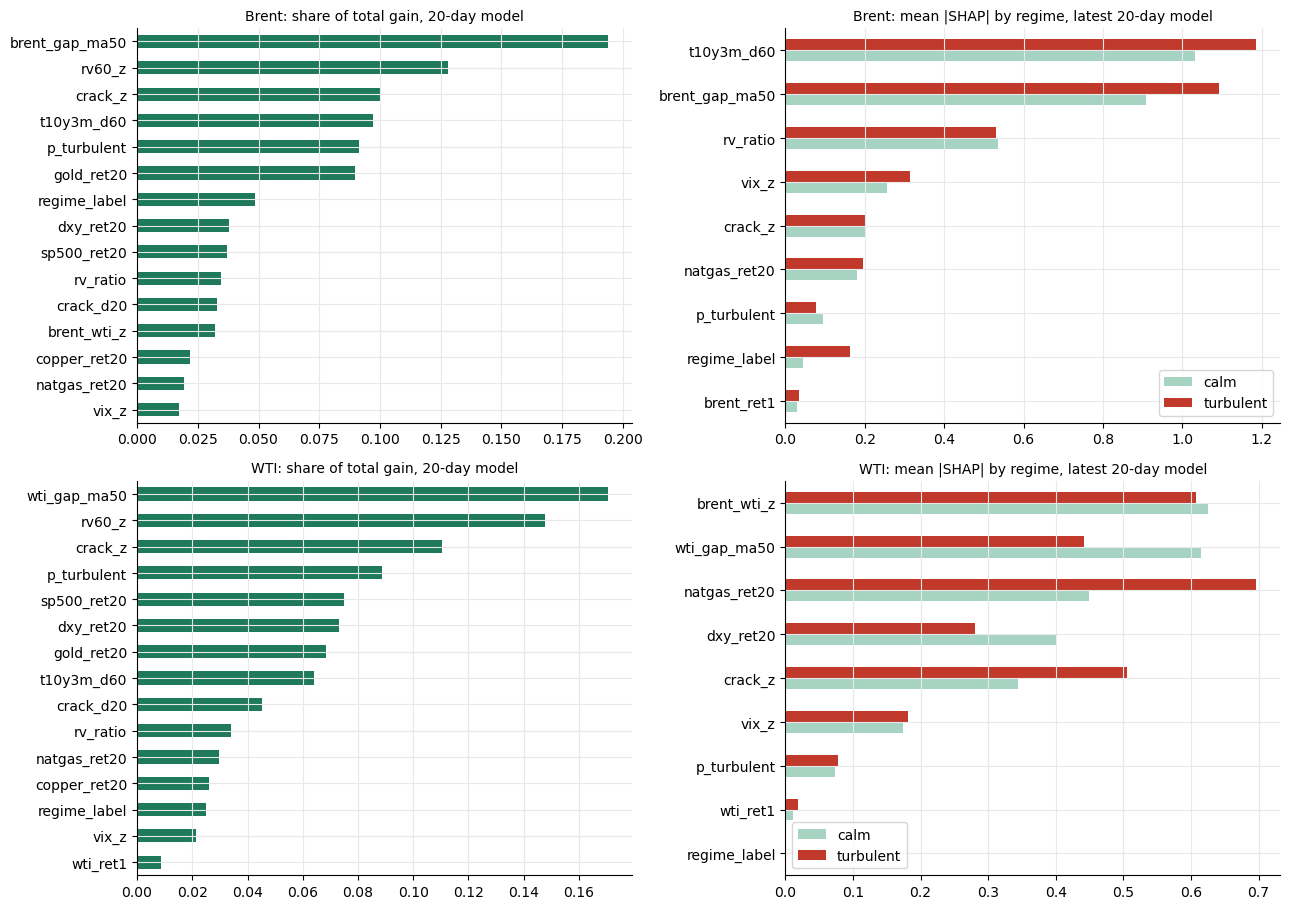

In [12]:
fig, axes = plt.subplots(NT, 2, figsize=(13, 4.6 * NT), squeeze=False)
for j, t in enumerate(cfg.targets):
    d = DATA[t]
    imp_h = d["importance"][d["importance"]["h"] == cfg.plot_h].drop(columns=["refit", "h"])
    share = imp_h.div(imp_h.sum(axis=1), axis=0).mean().sort_values(ascending=False)
    share.to_csv(OUT[t] / f"importance_h{cfg.plot_h}.csv")
    d["share"] = share
    e = d["ins"][cfg.plot_h]
    rows = e["rows"]
    contrib = e["model"].get_booster().predict(xgb.DMatrix(e["As"][rows]), pred_contribs=True)[:, :-1]
    shap = pd.DataFrame(contrib, columns=e["names"], index=d["X"].index[rows])
    turb = d["reg"]["label"].iloc[rows].to_numpy() == 1
    by_regime = pd.DataFrame({"turbulent": shap[turb].abs().mean() if turb.any() else np.nan,
                              "calm": shap[~turb].abs().mean() if (~turb).any() else np.nan})
    by_regime["all days"] = shap.abs().mean()
    by_regime = by_regime.sort_values("all days", ascending=False)
    by_regime.to_csv(OUT[t] / f"shap_by_regime_h{cfg.plot_h}.csv")
    d["by_regime"] = by_regime
    share.head(15)[::-1].plot.barh(ax=axes[j, 0], color="#1F7A5A")
    axes[j, 0].set_title(f"{NAMES[t]}: share of total gain, {cfg.plot_h}-day model", fontsize=10)
    by_regime.head(12)[["calm", "turbulent"]][::-1].plot.barh(ax=axes[j, 1], color=["#A7D3C2", "#C0392B"])
    axes[j, 1].set_title(f"{NAMES[t]}: mean |SHAP| by regime, latest {cfg.plot_h}-day model", fontsize=10)
fig.tight_layout(); fig.savefig(cfg.output_dir / "importance.png", dpi=150); plt.show()

### 6.4 Robustness

Out-of-sample price RMSE ratio vs RW, split by the regime label at the forecast origin and by year.
Then the same backtest with (a) all candidate features instead of the PCA subset and (b) no regime inputs.

In [13]:
def ratio_by(df, key):
    f = lambda g: np.sqrt(((g["P_t"] * np.exp(g["XGB"]) - g["P_target"]) ** 2).mean()
                          / ((g["P_t"] - g["P_target"]) ** 2).mean())
    df = df[df["h"].isin(cfg.report_h)]
    return df.groupby([key, "h"])[["P_t", "XGB", "P_target"]].apply(f).unstack("h").round(3)


for t in cfg.targets:
    d = DATA[t]
    o = d["fc"][d["fc"]["sample"] == "Out-of-sample"].dropna(subset=["y"]).copy()
    o["regime"] = o["origin"].map(d["reg"]["label"]).map({0.0: "calm", 1.0: "turbulent"})
    o["year"] = o["origin"].dt.year
    rob_reg, rob_year = ratio_by(o, "regime"), ratio_by(o, "year")
    rob_reg.to_csv(OUT[t] / "robustness_regime.csv"); rob_year.to_csv(OUT[t] / "robustness_year.csv")
    display(Markdown(f"**{NAMES[t]}: by regime**")); display(rob_reg)
    display(Markdown(f"**{NAMES[t]}: by year**")); display(rob_year)

**Brent: by regime**

h,1,5,10,20,30,40,50,60
regime,,,,,,,,
calm,1.001,1.006,1.001,1.000,1.003,1.000,0.997,0.997
turbulent,1.001,1.003,0.999,0.999,0.991,0.999,1.018,1.022


**Brent: by year**

h,1,5,10,20,30,40,50,60
year,,,,,,,,
2016,1.002,1.005,1.011,1.015,0.998,1.003,0.998,0.994
2017,1.003,1.000,1.001,1.004,1.003,0.998,1.001,1.001
2018,0.995,0.995,0.986,0.999,0.999,0.999,1.000,1.000
2019,1.008,1.025,1.002,1.005,1.005,1.001,0.999,1.001
2020,1.000,1.000,0.990,0.986,0.988,0.993,0.992,1.001
2021,1.000,1.004,0.995,1.005,1.040,1.038,0.994,0.994
2022,1.002,1.002,0.999,0.994,0.967,0.986,1.010,1.003
2023,1.002,1.001,0.997,0.995,0.999,0.985,0.975,0.979
2024,1.000,1.000,1.024,1.017,0.994,0.991,1.079,1.080


**WTI: by regime**

h,1,5,10,20,30,40,50,60
regime,,,,,,,,
calm,1.000,1.003,1.001,0.997,1.005,1.005,1.002,0.999
turbulent,1.001,0.997,0.999,0.993,0.998,1.002,1.007,0.995


**WTI: by year**

h,1,5,10,20,30,40,50,60
year,,,,,,,,
2016,1.000,1.003,1.003,1.005,0.999,1.000,1.005,1.010
2017,1.001,1.002,1.003,1.002,1.001,1.001,1.002,1.004
2018,0.995,0.992,0.993,0.997,1.000,1.000,1.000,1.000
2019,1.002,1.008,0.990,0.993,1.043,1.033,1.017,1.010
2020,1.000,1.001,0.998,0.995,1.005,1.011,1.015,1.012
2021,1.002,1.003,0.999,0.994,1.024,1.007,1.007,0.999
2022,1.001,1.000,0.998,0.980,0.986,1.000,0.985,0.996
2023,0.999,0.997,0.999,0.998,0.998,1.002,0.996,0.953
2024,1.000,1.004,1.005,1.022,1.027,0.964,0.949,0.970


In [14]:
def oos_summary(df):
    g = df[(df["sample"] == "Out-of-sample") & df["h"].isin(cfg.report_h)].dropna(subset=["y"])
    rmse = g.groupby("h").apply(lambda d: np.sqrt(((d["P_t"] * np.exp(d["XGB"]) - d["P_target"]) ** 2).mean()
                                                 / ((d["P_t"] - d["P_target"]) ** 2).mean()), include_groups=False)
    ic = g.groupby("h").apply(lambda d: stats.spearmanr(d["XGB"], d["y"]).correlation, include_groups=False)
    return rmse, ic


variants = {"main (PCA + regime)": cfg, "all candidates + regime": replace(cfg, use_pca=False),
            "PCA, no regime": replace(cfg, use_regime=False)}
comp = {}
for t in cfg.targets:
    d = DATA[t]
    for vname, vc in variants.items():
        if vc is cfg:
            fcv = d["fc"]
        else:
            vc = replace(vc, horizons=cfg.report_h)
            ov = run_backtest(d["X"], d["Y"], d["lp"], d["vol"], d["reg"], vc, verbose=False)[0]
            fcv = to_long({h: {"XGB": ov[h]["XGB"]} for h in vc.horizons}, d["lp"],
                          {h: np.flatnonzero(np.isfinite(ov[h]["XGB"])) for h in vc.horizons})
        r_, ic_ = oos_summary(fcv)
        comp[(NAMES[t], "RMSE ratio vs RW", vname)] = r_
        comp[(NAMES[t], "IC", vname)] = ic_
comp = pd.DataFrame(comp).T.round(3)
comp.to_csv(cfg.output_dir / "robustness_variants.csv")
display(comp)

h                                                  1      5      10     20     30     40     50     60
Brent RMSE ratio vs RW main (PCA + regime)      1.001  1.005  1.001  1.000  0.999  1.000  1.003  1.004
      IC               main (PCA + regime)     -0.018 -0.024  0.038  0.069  0.089  0.108  0.102  0.046
      RMSE ratio vs RW all candidates + regime  1.000  1.001  1.002  0.992  1.000  0.997  0.995  0.996
      IC               all candidates + regime  0.001  0.004  0.038  0.117  0.184  0.174  0.191  0.150
      RMSE ratio vs RW PCA, no regime           1.001  1.005  1.005  1.007  1.007  1.005  1.002  0.998
      IC               PCA, no regime          -0.009 -0.004  0.000  0.009 -0.010 -0.001  0.021  0.100
WTI   RMSE ratio vs RW main (PCA + regime)      1.000  1.001  1.000  0.996  1.003  1.004  1.003  0.998
      IC               main (PCA + regime)      0.001  0.017  0.022  0.061  0.046 -0.036 -0.026  0.042
      RMSE ratio vs RW all candidates + regime  1.001  1.001  1.000  1.001  0.999  0.997  0.995  0.996
      IC               all candidates + regime  0.027  0.010  0.048  0.058  0.129  0.155  0.168  0.201
      RMSE ratio vs RW PCA, no regime           1.000  1.002  1.001  0.999  1.002  1.004  0.996  0.996
      IC               PCA, no regime           0.003 -0.002  0.016  0.071  0.010  0.000  0.092  0.119

### 6.5 Economic value

All rules are fixed here, before the results, and every variant is reported. $H$ is the holding period and
equals the forecast horizon used; the main rule is $H=20$, and $H=5, 10$ are shown as robustness.

**Strategy (Brent and WTI separately).** Each day: long if the $H$-day forecast is positive, short if negative, size
$\min(2,\ 25\%/\sigma^{ann}_t)$ with $\sigma^{ann}_t$ the 20-day realized volatility. No position when the forecast is
small relative to risk: $|\hat y_{t,H}| \le 0.1\,\sigma_{t,H}$ ($\sigma$ scaled to $H$ days).

**Overlapping tranches.** Each day a new tranche of $1/H$ of capital is opened on that day's signal and held
for $H$ days, so the position is the average of the last $H$ daily signals. This removes the luck of a single
rebalancing date. Costs: 5 bp per unit of change in the position.

**Benchmarks.** Buy and hold (position 1) and a vol-targeted long position ($\min(2,\ 25\%/\sigma^{ann}_t)$, always long).

**Comparing returns.** The strategy holds a position only part of the time and its long and short tranches
partly offset, so its volatility is far below buy-and-hold and raw returns are not comparable. The last
column rescales each strategy to 10% annual volatility (return × 10% / its volatility), the same comparison as
the Sharpe ratio in return units. The chart shows the same rescaled cumulative returns.

annual return %  annual vol %  Sharpe  max drawdown %  days with a position %  turnover per year  return at 10% vol %
target strategy                                                                                                                                
Brent  XGBoost, H = 5               -3.58          7.08   -0.51          -32.86                   14.85               3.97                -5.06
       XGBoost, H = 10               2.49          7.35    0.34          -21.24                   19.82               2.14                 3.38
       XGBoost, H = 20               2.01          9.41    0.21          -18.70                   32.43               2.08                 2.13
       Long vol-targeted             5.20         28.36    0.18          -53.68                  100.00               9.22                 1.83
       Buy and hold                 10.21         41.77    0.24          -77.60                  100.00               0.09                 2.45
WTI    XGBoost, H = 5               -1.39          8.31   -0.17          -29.68                   20.40               5.84                -1.67
       XGBoost, H = 10               0.82          8.47    0.10          -24.05                   24.82               3.50                 0.97
       XGBoost, H = 20               4.46          8.80    0.51          -17.79                   35.04               2.42                 5.07
       Long vol-targeted             2.72         28.11    0.10          -61.46                  100.00               8.22                 0.97
       Buy and hold                  9.21         49.94    0.18          -86.90                  100.00               0.09                 1.84

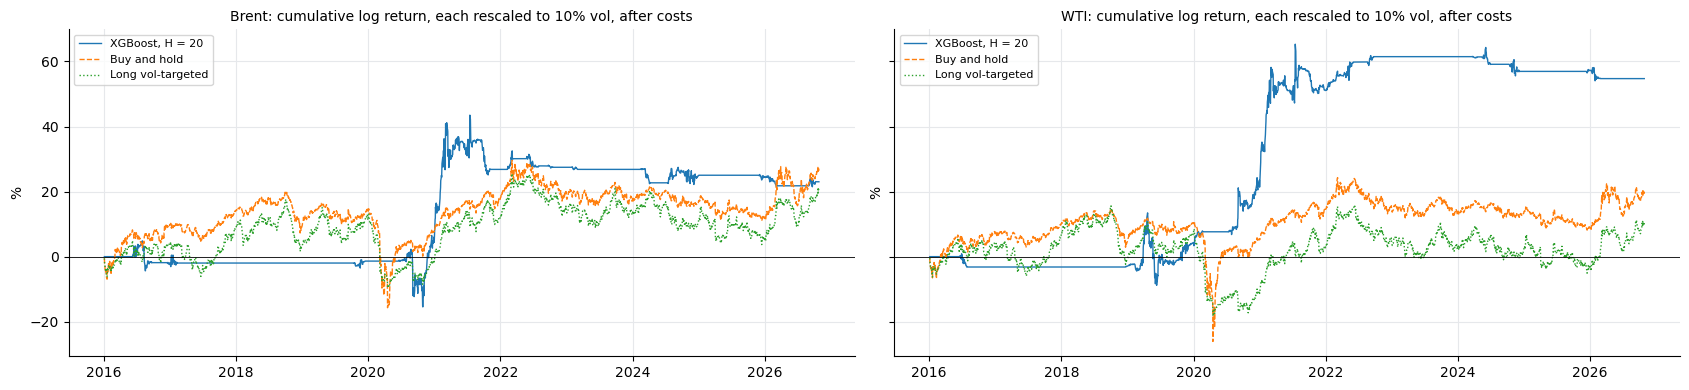

In [15]:
def daily_ret(t):
    fc = DATA[t]["fc"]
    return fc[(fc["h"] == 1) & fc["sample"].isin(["Out-of-sample", "Live test"])].dropna(subset=["y"]).set_index("origin")["y"]


def signal(t, H):
    fc = DATA[t]["fc"]
    return fc[(fc["h"] == H)].drop_duplicates("origin").set_index("origin")["XGB"]


def tranche(w, H):
    return w.fillna(0.0).rolling(H, min_periods=1).sum() / H


def run_rule(pos, ret):
    pos = pos.reindex(ret.index).fillna(0.0)
    turn = pos.diff().abs().fillna(pos.abs())
    return pos * ret - cfg.cost_bps / 1e4 * turn, pos, turn


def perf(pnl, pos, turn):
    cum = pnl.cumsum()
    vol = np.sqrt(252) * pnl.std()
    return {"annual return %": 100 * 252 * pnl.mean(), "annual vol %": 100 * vol,
            "Sharpe": 252 * pnl.mean() / vol if vol > 0 else np.nan,
            "max drawdown %": 100 * (np.exp((cum - cum.cummax()).min()) - 1),
            "days with a position %": 100 * (pos.abs() > 1e-9).mean(), "turnover per year": 252 * turn.mean(),
            f"return at {cfg.compare_vol:.0f}% vol %": cfg.compare_vol * 252 * pnl.mean() / vol if vol > 0 else np.nan}


rows_e, pnls = [], {}
for t in cfg.targets:
    ret = daily_ret(t)
    rv = DATA[t]["vol"]["rv20"].reindex(ret.index)
    size = np.minimum(cfg.max_leverage, cfg.target_vol / (100 * rv))
    for H in cfg.trade_hs:
        f = signal(t, H).reindex(ret.index)
        w = np.sign(f) * size * (f.abs() > cfg.noise_k * rv * np.sqrt(H / 252))
        pnl, pos, turn = run_rule(tranche(w, H), ret)
        rows_e.append({"target": NAMES[t], "strategy": f"XGBoost, H = {H}", **perf(pnl, pos, turn)})
        pnls[(t, f"XGBoost, H = {H}")] = pnl
    for name, pos in (("Long vol-targeted", size), ("Buy and hold", pd.Series(1.0, index=ret.index))):
        pnl, pos_, turn = run_rule(pos, ret)
        rows_e.append({"target": NAMES[t], "strategy": name, **perf(pnl, pos_, turn)})
        pnls[(t, name)] = pnl
econ = pd.DataFrame(rows_e).set_index(["target", "strategy"]).round(2)
econ.to_csv(cfg.output_dir / "economic_value.csv")
display(econ)

fig, axes = plt.subplots(1, NT, figsize=(7 * NT + 3, 4), sharey=True, squeeze=False)
for ax, t in zip(axes[0], cfg.targets):
    for name, ls in ((f"XGBoost, H = {cfg.main_trade_h}", "-"), ("Buy and hold", "--"), ("Long vol-targeted", ":")):
        pnl = pnls[(t, name)]
        scaled = pnl * cfg.compare_vol / 100 / (np.sqrt(252) * pnl.std())
        ax.plot(scaled.index, 100 * scaled.cumsum(), ls=ls, lw=1.0, label=name)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(f"{NAMES[t]}: cumulative log return, each rescaled to {cfg.compare_vol:.0f}% vol, after costs", fontsize=10)
    ax.set_ylabel("%"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(cfg.output_dir / "equity_curves.png", dpi=150); plt.show()

**By regime.** Sharpe ratio of the XGBoost rule on days labelled calm vs turbulent (label of the same oil).

In [16]:
rows_r = []
for t in cfg.targets:
    lab = DATA[t]["reg"]["label"]
    for H in cfg.trade_hs:
        pnl = pnls[(t, f"XGBoost, H = {H}")]
        for name, v in (("calm", 0), ("turbulent", 1)):
            p_ = pnl[(lab.reindex(pnl.index) == v).to_numpy()]
            rows_r.append({"target": NAMES[t], "H": H, "regime": name, "days": len(p_),
                           "annual return %": 100 * 252 * p_.mean(),
                           "Sharpe": np.sqrt(252) * p_.mean() / p_.std() if p_.std() > 0 else np.nan})
by_reg = pd.DataFrame(rows_r).set_index(["target", "H", "regime"]).round(2)
by_reg.to_csv(cfg.output_dir / "economic_value_by_regime.csv")
display(by_reg)

days  annual return %  Sharpe
target H  regime                                  
Brent  5  calm       1928            -6.05   -0.81
          turbulent   792             2.42    0.40
       10 calm       1928             2.49    0.29
          turbulent   792             2.49    0.71
       20 calm       1928             3.04    0.28
          turbulent   792            -0.52   -0.17
WTI    5  calm       2059            -1.31   -0.15
          turbulent   661            -1.63   -0.23
       10 calm       2059             0.64    0.07
          turbulent   661             1.37    0.22
       20 calm       2059             4.80    0.49
          turbulent   661             3.41    0.73

## 7. Latest forecast

Re-trained on the most recent window for each target and horizon, forecast from the last observed close.
Each run appends to `forecast_log.csv`, the record for the live test period.

**Brent** (regime: calm)

,target_date,price_now,forecast_price,forecast_ret_%,lo95,lo80,hi80,hi95
h,,,,,,,,
1,2026-10-29,110.82,110.75,-0.06,104.19,107.30,114.26,116.54
5,2026-11-04,110.82,110.81,-0.01,96.58,102.51,119.28,126.49
10,2026-11-11,110.82,110.78,-0.04,91.07,99.14,122.79,134.00
20,2026-11-25,110.82,110.77,-0.04,87.68,94.85,129.03,143.80
30,2026-12-09,110.82,110.97,0.13,85.85,94.06,130.58,163.62
40,2026-12-23,110.82,110.92,0.09,78.96,91.01,136.45,179.26
50,2027-01-06,110.82,111.03,0.19,77.66,91.93,141.07,191.88
60,2027-01-20,110.82,110.97,0.13,75.17,90.17,147.19,197.13


**WTI** (regime: calm)

,target_date,price_now,forecast_price,forecast_ret_%,lo95,lo80,hi80,hi95
h,,,,,,,,
1,2026-10-29,102.08,102.06,-0.02,95.99,98.42,105.55,107.99
5,2026-11-04,102.08,102.08,0.00,89.05,94.38,110.47,117.35
10,2026-11-11,102.08,102.07,-0.01,84.93,91.10,113.42,125.45
20,2026-11-25,102.08,102.05,-0.03,81.25,87.95,118.50,136.48
30,2026-12-09,102.08,102.02,-0.06,76.64,85.10,121.82,151.20
40,2026-12-23,102.08,102.14,0.06,71.42,83.24,125.27,165.93
50,2027-01-06,102.08,101.94,-0.13,70.50,84.52,129.39,180.18
60,2027-01-20,102.08,110.06,7.53,81.88,91.67,137.39,196.58


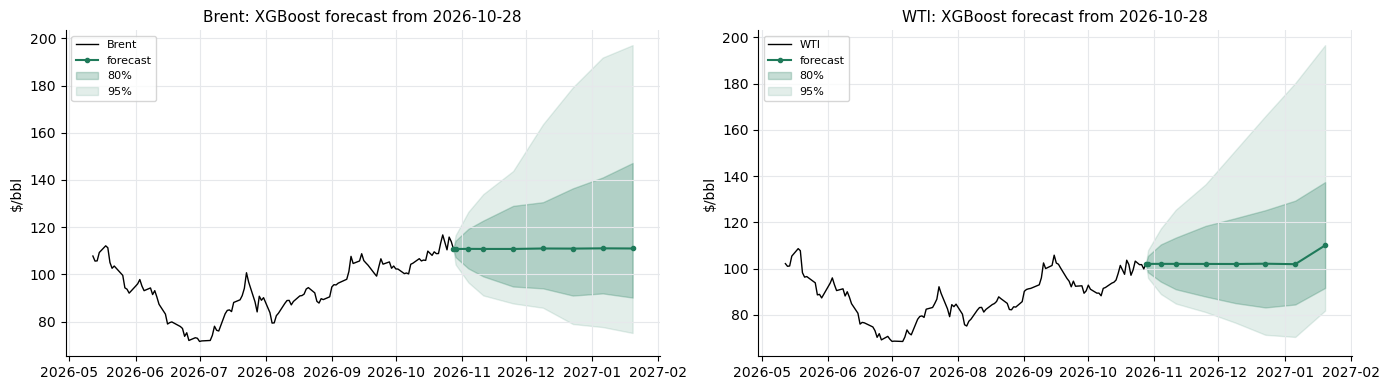

In [17]:
live_all = {}
for t in cfg.targets:
    d = DATA[t]
    X, N = d["X"], len(d["X"])
    A_all = X.to_numpy(np.float32)
    R_all = d["reg"][["p_turb", "label"]].to_numpy(np.float32)
    sel_live = pca_select(A_all[N - cfg.window:N], X.columns, cfg.pca_min_eig)[0] if cfg.use_pca else list(range(X.shape[1]))
    A_live = design(A_all, R_all, sel_live, cfg)
    P0, d0 = prices[t].iloc[-1], prices.index[-1]
    rows_l = []
    for h in cfg.horizons:
        scale = 100 * d["vol"]["rv20"].to_numpy() * np.sqrt(h / 252)
        m, q, _, _ = fit_one(A_live, d["Y"][h].to_numpy(), scale, N - 1, h, cfg)
        mu = cfg.shrink * float(m.predict(A_live[N - 1:N])[0]) / 100
        q = q * scale[N - 1] / 100
        rows_l.append({"asof": str(d0.date()), "h": h, "target_date": (d0 + pd.offsets.BDay(h)).date(),
                       "price_now": P0, "forecast_price": P0 * np.exp(mu), "forecast_ret_%": 100 * mu,
                       "lo95": P0 * np.exp(mu + q[0]), "lo80": P0 * np.exp(mu + q[1]),
                       "hi80": P0 * np.exp(mu + q[2]), "hi95": P0 * np.exp(mu + q[3]),
                       "regime": "turbulent" if d["reg"]["label"].iloc[-1] == 1 else "calm"})
    live = pd.DataFrame(rows_l)
    live.to_csv(OUT[t] / "live_forecast.csv", index=False)
    log_path = OUT[t] / "forecast_log.csv"
    flog = pd.concat([pd.read_csv(log_path), live]) if log_path.exists() else live
    flog.drop_duplicates(["asof", "h"], keep="last").to_csv(log_path, index=False)
    live_all[t] = live
    display(Markdown(f"**{NAMES[t]}** (regime: {live['regime'].iloc[0]})"))
    display(live[live["h"].isin(cfg.report_h)].set_index("h").drop(columns=["asof", "regime"]).round(2))

fig, axes = plt.subplots(1, NT, figsize=(6.5 * NT + 1, 4), squeeze=False)
for ax, t in zip(axes[0], cfg.targets):
    live = live_all[t]
    hist = prices[t].iloc[-120:]
    d0, P0 = prices.index[-1], prices[t].iloc[-1]
    td = [d0] + [pd.Timestamp(x) for x in live["target_date"]]
    col = lambda c: [P0] + list(live[c])
    ax.plot(hist.index, hist, color="black", lw=1, label=NAMES[t])
    ax.plot(td, col("forecast_price"), color="#1F7A5A", lw=1.5, marker="o", ms=3, label="forecast")
    ax.fill_between(td, col("lo80"), col("hi80"), color="#1F7A5A", alpha=0.25, label="80%")
    ax.fill_between(td, col("lo95"), col("hi95"), color="#1F7A5A", alpha=0.12, label="95%")
    ax.set_title(f"{NAMES[t]}: XGBoost forecast from {d0.date()}", fontsize=11)
    ax.set_ylabel("$/bbl"); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.savefig(cfg.output_dir / "fan_chart.png", dpi=150); plt.show()

## 8. Takeaways

In [18]:
lines = []
for t in cfg.targets:
    d = DATA[t]
    o_x = d["xm"][d["xm"]["sample"] == "Out-of-sample"].set_index("h")
    wins = int((o_x["RMSE_ratio_vs_RW"] < 1).sum())
    sig_h = list(o_x.index[o_x["DM_p"] < 0.05])
    lines.append(f"**{NAMES[t]}**: lower price RMSE than RW at {wins} of {len(o_x)} horizons "
                 f"(ratios {o_x['RMSE_ratio_vs_RW'].min():.3f} to {o_x['RMSE_ratio_vs_RW'].max():.3f}); "
                 + (f"significant at 5% (DM) at h = {sig_h}. " if sig_h else "none significant at 5% (DM). ")
                 + f"Hit rate {o_x['hit_%'].min():.0f}% to {o_x['hit_%'].max():.0f}%. "
                 f"80% / 95% interval coverage {o_x['cover80_%'].min():.0f}–{o_x['cover80_%'].max():.0f}% / "
                 f"{o_x['cover95_%'].min():.0f}–{o_x['cover95_%'].max():.0f}%. "
                 f"Top {cfg.plot_h}-day feature: `{d['share'].index[0]}`.")
for t in cfg.targets:
    e = econ.loc[NAMES[t]]
    lines.append(f"**Economic value, {NAMES[t]}** (Sharpe after costs): "
                 + ", ".join(f"{k} {e.loc[k, 'Sharpe']:.2f}" for k in e.index) + ".")
display(Markdown("\n".join("- " + s for s in lines)))

- **Brent**: lower price RMSE than RW at 3 of 8 horizons (ratios 0.999 to 1.005); none significant at 5% (DM). Hit rate 49% to 57%. 80% / 95% interval coverage 76–80% / 91–95%. Top 20-day feature: `brent_gap_ma50`.
- **WTI**: lower price RMSE than RW at 2 of 8 horizons (ratios 0.996 to 1.004); none significant at 5% (DM). Hit rate 48% to 51%. 80% / 95% interval coverage 78–80% / 92–95%. Top 20-day feature: `wti_gap_ma50`.
- **Economic value, Brent** (Sharpe after costs): XGBoost, H = 5 -0.51, XGBoost, H = 10 0.34, XGBoost, H = 20 0.21, Long vol-targeted 0.18, Buy and hold 0.24.
- **Economic value, WTI** (Sharpe after costs): XGBoost, H = 5 -0.17, XGBoost, H = 10 0.10, XGBoost, H = 20 0.51, Long vol-targeted 0.10, Buy and hold 0.18.

## 9. Look-ahead check (optional)

Scrambles all data after a cut-off date, re-runs a short Brent backtest (regimes included), and checks that every
forecast made on or before the cut-off is unchanged.

In [19]:
if RUN_LEAK_CHECK:
    cut, end = pd.Timestamp("2021-06-30"), "2022-06-30"
    c2 = replace(cfg, oos_start="2020-06-01", horizons=(1, 20))
    rng = np.random.default_rng(0)
    p2, o2 = prices.copy(), other.copy()
    after = p2.index > cut
    p2.loc[after] = p2.loc[after] * np.exp(rng.normal(0, 0.05, (after.sum(), p2.shape[1])))
    o2.loc[o2.index > cut] = o2.loc[o2.index > cut] * np.exp(rng.normal(0, 0.05, o2.loc[o2.index > cut].shape))
    res = []
    for pp_, oo_ in ((prices, other), (p2, o2)):
        Xc, Yc, lc, vc = build_features(pp_.loc[:end], oo_.loc[:end], "brent_fut", c2)
        rc = regime_path(lc, c2)[0]
        res.append(run_backtest(Xc, Yc, lc, vc, rc, c2, verbose=False)[0])
    k = int(Xc.index.searchsorted(cut, side="right"))
    before = max(np.nanmax(np.abs(res[0][h][m][:k] - res[1][h][m][:k])) for h in c2.horizons
                 for m in ("XGB", "q975", "AR", "HistMean"))
    later = np.nanmax(np.abs(res[0][20]["XGB"][k:] - res[1][20]["XGB"][k:]))
    print(f"max change on/before cut-off: {before:.2e}   after: {later:.2e}")
    print("PASS: no look-ahead" if before < 1e-9 and later > 0 else "FAIL")